# Student Performance Prediction

## Machine Learning Modeling

### Project Overview

The objective of this project is to predict a student's final grade based on their study habits, attendance, and previous academic performance.

The target variable is **G3**, which represents the student's final grade in Mathematics on a scale from 0 to 20.

Based on the exploratory data analysis, the following variables were selected as features:

- `studytime` — weekly study time
- `absences` — number of school absences
- `G1` — first-period grade
- `G2` — second-period grade

The target variable is:

- `G3` — final grade

### Modeling Approach

The modeling stage will follow these steps:

1. Load and prepare the dataset.
2. Select the features and target variable.
3. Split the data into training and testing sets.
4. Establish a baseline model.
5. Train a Linear Regression model.
6. Train a Random Forest Regression model.
7. Evaluate the models using MAE, RMSE, and R².
8. Compare the models and select the best-performing model.

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 1. Load the Dataset

The Mathematics student performance dataset used during the EDA stage will be loaded for the modeling process.

In [2]:
df = pd.read_csv("../data/student-mat.csv", sep=";")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 2. Feature and Target Selection

Based on the EDA findings, four variables were selected as predictors:

- `studytime`
- `absences`
- `G1`
- `G2`

The final grade `G3` is used as the target variable.

The model is designed to predict the final grade after the second-period grade (`G2`) is available.

In [3]:
features = ["studytime", "absences", "G1", "G2"]

X = df[features]
y = df["G3"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   studytime  absences  G1  G2
0          2         6   5   6
1          2         4   5   5
2          2        10   7   8
3          3         2  15  14
4          2         4   6  10

Target:
0     6
1     6
2    10
3    15
4    10
Name: G3, dtype: int64


## 3. Train-Test Split

The dataset will be divided into training and testing sets.

- **80%** of the data will be used for training.
- **20%** will be reserved for testing.

A fixed random state of 42 is used to make the results reproducible.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)

Training set size: (316, 4)
Testing set size: (79, 4)


## 4. Baseline Model — Linear Regression

Linear Regression is used as the baseline machine learning model.

It provides a simple and interpretable reference point against which more complex models can be compared.

The model will learn the relationship between the selected features (`studytime`, `absences`, `G1`, and `G2`) and the target variable (`G3`).

The performance of the baseline model will be evaluated using:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R² Score

In [5]:
from sklearn.linear_model import LinearRegression

# Create the baseline model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train, y_train)



,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[-0.05, 0.04, 0.17, 0.99]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['studytime','absences','G1','G2']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2.202
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [6]:
# Make predictions
linear_predictions = linear_model.predict(X_test)

# Evaluate the model
linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        linear_predictions
    )
)

linear_r2 = r2_score(
    y_test,
    linear_predictions
)

print("Linear Regression Results")
print("-------------------------")
print("MAE:", linear_mae)
print("RMSE:", linear_rmse)
print("R²:", linear_r2)

Linear Regression Results
-------------------------
MAE: 1.3125749396243551
RMSE: 2.0442542421105148
R²: 0.7961977189442985


## Interpretation of Linear Regression Results

The Linear Regression model achieved the following results on the test set:

- **MAE: 1.31**
- **RMSE: 2.04**
- **R²: 0.7962**

The **Mean Absolute Error (MAE) of 1.31** indicates that, on average, the model's predictions differ from the students' actual final grades by approximately **1.31 grade points**.

The **Root Mean Squared Error (RMSE) of 2.04** indicates that the model has an average prediction error of approximately **2.04 grade points**, with larger errors receiving greater weight than in MAE.

The **R² score of 0.7962** indicates that the model explains approximately **79.62% of the variation in students' final grades** using the selected features: `studytime`, `absences`, `G1`, and `G2`.

Overall, the Linear Regression model provides a strong baseline for the prediction task. However, there may be non-linear relationships in the data that a more complex model could capture. Therefore, a **Random Forest Regression model** will be trained next to determine whether it can improve upon the baseline performance.

## 5. Reusable Data Pipeline

The initial baseline model was developed using direct data loading and train-test splitting. In this section, the project introduces reusable data ingestion and transformation components to make the machine learning workflow more organized, consistent, and maintainable.

The pipeline loads and validates the dataset, separates it into training and testing sets, selects the required features, and applies preprocessing before model training.

In [ ]:
from src.components.data_ingestion import DataIngestion
from src.components.data_transformation import DataTransformation

print("Both components imported successfully!")

In [11]:
import os
import sys

project_root = r"C:\Users\helle\Desktop\Predictive-analytics-project"

os.chdir(project_root)

if project_root not in sys.path:
    sys.path.insert(0, project_root)

print("Working directory:", os.getcwd())
print(
    "Dataset exists:",
    os.path.isfile("data/student-mat.csv")
)

Working directory: C:\Users\helle\Desktop\Predictive-analytics-project
Dataset exists: True


In [12]:
train_path, test_path = DataIngestion().initiate_data_ingestion()

X_train, y_train, X_test, y_test = (
    DataTransformation().initiate_data_transformation(
        train_path, test_path
    )
)

print("Training features:", X_train.shape)
print("Training target:", y_train.shape)
print("Testing features:", X_test.shape)
print("Testing target:", y_test.shape)

Dataset loaded successfully!
Dataset shape: (395, 33)
Training features: (316, 4)
Training target: (316,)
Testing features: (79, 4)
Testing target: (79,)


## 6. Final Model Training and Evaluation

In this section, Linear Regression and Random Forest Regression are trained using the reusable data pipeline. Both models use the same training and testing sets, allowing their performance to be compared fairly using MAE, RMSE, and R².

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

print("Model imports successful!")

Model imports successful!


In [15]:
# Define the models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
}

results = []

# Train and evaluate each model
for name, model in models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    })

# Display the comparison
results_df = pd.DataFrame(results)

print("Final Model Comparison")
print(results_df.round(4).to_string(index=False))

Final Model Comparison
            Model    MAE   RMSE     R²
Linear Regression 1.3126 2.0443 0.7962
    Random Forest 1.1302 1.8139 0.8395


## 7. Model Comparison and Interpretation

The Linear Regression and Random Forest Regression models were evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² on the same held-out test set.

Linear Regression achieved an MAE of 1.3126, an RMSE of 2.0443, and an R² score of 0.7962. Random Forest achieved an MAE of 1.1302, an RMSE of 1.8139, and an R² score of 0.8395.

Random Forest outperformed Linear Regression across all three evaluation metrics. Its lower MAE indicates that its predictions were closer to the actual final grades on average. Its lower RMSE indicates better performance in terms of squared prediction errors, while its higher R² score indicates that it explained a greater proportion of the variation in final grades.

Based on these results, Random Forest Regression is selected as the best-performing model among the two models evaluated. However, this conclusion is based on the current test split, and further validation would help assess how well the model generalizes to unseen students.

## 8. Actual vs. Predicted Grades

This section visualizes the actual final grades against the grades predicted by the Random Forest Regression model. The visualization helps assess how closely the predictions match the observed grades. Predictions closer to the diagonal reference line indicate better agreement between actual and predicted values.

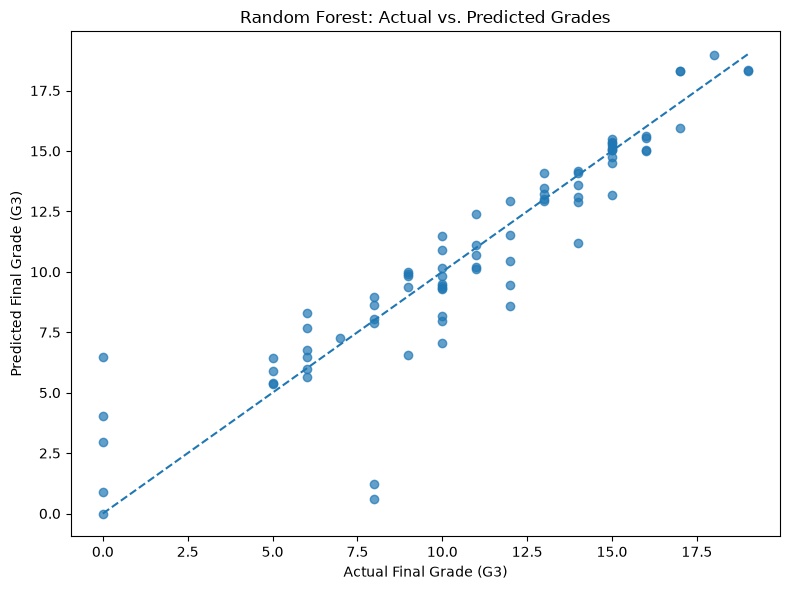

In [17]:
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor

# Create and train the selected Random Forest model
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

random_forest_model.fit(X_train, y_train)

# Predict grades for the test set
rf_predictions = random_forest_model.predict(X_test)

# Plot actual versus predicted grades
plt.figure(figsize=(8, 6))

plt.scatter(y_test, rf_predictions, alpha=0.7)

# Reference line for perfect predictions
min_grade = min(y_test.min(), rf_predictions.min())
max_grade = max(y_test.max(), rf_predictions.max())

plt.plot(
    [min_grade, max_grade],
    [min_grade, max_grade],
    linestyle="--"
)

plt.xlabel("Actual Final Grade (G3)")
plt.ylabel("Predicted Final Grade (G3)")
plt.title("Random Forest: Actual vs. Predicted Grades")

plt.tight_layout()
plt.show()

### Interpretation of Actual vs. Predicted Grades

The scatter plot shows the relationship between the actual final grades and the grades predicted by the Random Forest Regression model. The dashed diagonal line represents perfect predictions, where the predicted grade equals the actual grade.

Most points lie relatively close to the diagonal line, suggesting that the model predicts many students' final grades reasonably well. However, some points are farther from the line, indicating larger prediction errors.

The plot also shows that some students with low actual grades received higher predicted grades, while a few students with actual grades around 8–12 received lower predictions. This suggests that the model does not predict every student's grade equally accurately.

Overall, the visualization supports the evaluation metrics, which indicate that Random Forest performs well on this test set. Nevertheless, the remaining prediction errors show that the model could be improved or further validated.

## 9. Feature Importance Analysis

Feature importance is used to examine the relative contribution of each input feature to the Random Forest model's predictions. This analysis helps identify which variables the model relies on most when predicting students' final grades.

  Feature  Importance
       G2      0.8227
 absences      0.1206
       G1      0.0344
studytime      0.0223


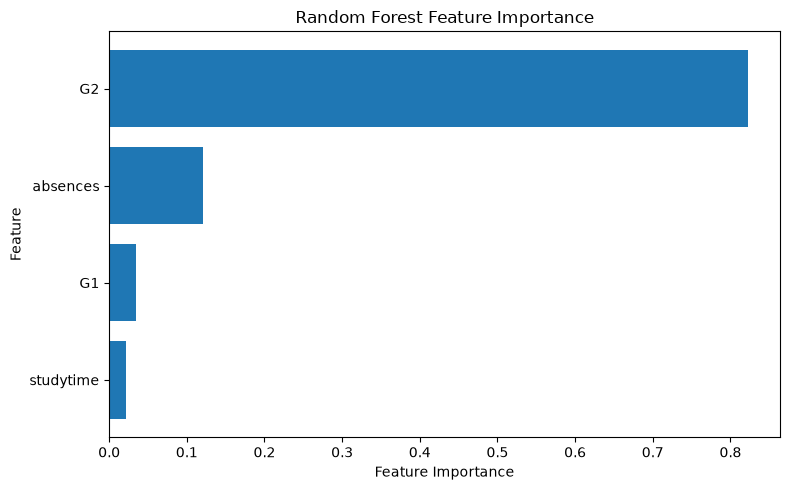

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance from the trained Random Forest model
feature_names = ["studytime", "absences", "G1", "G2"]

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": random_forest_model.feature_importances_
})

# Sort features from most to least important
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.round(4).to_string(index=False))

# Plot feature importance
plt.figure(figsize=(8, 5))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Interpretation of Feature Importance

The Random Forest feature importance analysis shows that `G2`, the second-period grade, is the most influential feature in predicting students' final Mathematics grades (`G3`). It accounts for the largest share of the model's total feature importance.

The number of absences (`absences`) is the second most important feature, while the first-period grade (`G1`) and weekly study time (`studytime`) have comparatively smaller importance scores.

These results suggest that recent academic performance plays a particularly important role in the model's predictions. However, feature importance reflects how the Random Forest model uses the selected variables; it does not establish causation or imply that less important variables are irrelevant to student performance.

## 10 Candidate Model Selection

In this section, three regression algorithms are selected for performance evaluation: Linear Regression, Random Forest Regressor, and XGBoost Regressor.

The models are selected to compare different approaches to regression:

- **Linear Regression:** A baseline statistical learning algorithm that models the relationship between input features and the target variable using a linear equation.
- **Random Forest Regressor:** An ensemble learning algorithm that combines predictions from multiple decision trees to improve predictive performance.
- **XGBoost Regressor:** A gradient boosting algorithm that builds decision trees sequentially, with each new tree attempting to improve the predictions made by previous trees.

The objective is to identify which algorithm provides the best predictive performance when estimating students' final Mathematics grades (G3).

All three models will be evaluated using the same training data and five-fold cross-validation to ensure a consistent comparison.

In [4]:
import sys
!{sys.executable} -m pip install xgboost

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)


In [5]:
import xgboost

print("XGBoost version:", xgboost.__version__)

XGBoost version: 3.4.1


In [6]:
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

from sklearn.model_selection import cross_val_score, KFold

In [7]:
models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ),

    "XGBoost": XGBRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

print("Candidate models prepared successfully!")

Candidate models prepared successfully!


## 10.2 Model Evaluation Using Five-Fold Cross-Validation

To obtain a more reliable estimate of model performance, five-fold cross-validation is used.

Cross-validation divides the training dataset into five approximately equal subsets, known as folds.

During each iteration, four folds are used to train the model, while the remaining fold is used for validation. This process is repeated five times, ensuring that every fold is used once for validation.

The five validation scores are then averaged to obtain an overall performance estimate.

For this regression problem, Mean Absolute Error (MAE) is selected as the evaluation metric. A lower MAE indicates better predictive performance.

This approach allows us to compare the consistency and predictive performance of the three candidate models before selecting a model for hyperparameter tuning.

In [10]:
import os
import sys

project_root = r"C:\Users\helle\Desktop\Predictive-analytics-project"

os.chdir(project_root)

if project_root not in sys.path:
    sys.path.insert(0, project_root)

print("Working directory:", os.getcwd())
print("Project directory exists:", os.path.isdir("src"))

Working directory: C:\Users\helle\Desktop\Predictive-analytics-project
Project directory exists: True


In [11]:
from src.components.data_ingestion import DataIngestion

# Run data ingestion again
train_path, test_path = DataIngestion().initiate_data_ingestion()

print("Training path:", train_path)
print("Testing path:", test_path)

Dataset loaded successfully!
Dataset shape: (395, 33)
Training path: artifacts\train.csv
Testing path: artifacts\test.csv


In [12]:
train_df = pd.read_csv(train_path)

features = ["studytime", "absences", "G1", "G2"]

X_train_raw = train_df[features]
y_train_raw = train_df["G3"]

print("Training features:", X_train_raw.shape)
print("Training target:", y_train_raw.shape)

Training features: (316, 4)
Training target: (316,)


To ensure consistent preprocessing during model evaluation, we create a pipeline that handles missing values and standardizes numerical features.

The SimpleImputer replaces missing values using the median, while StandardScaler standardizes the features.

We also configure five-fold cross-validation to evaluate the candidate models across different training and validation subsets. Preprocessing is included inside each model pipeline to prevent data leakage.

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold

# Create the numerical preprocessing pipeline
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Apply preprocessing to the selected features
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, features)
])

# Configure five-fold cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Preprocessing pipeline created successfully!")
print("Five-fold cross-validation configured!")

Preprocessing pipeline created successfully!
Five-fold cross-validation configured!


In this step, we evaluate Linear Regression, Random Forest Regressor and XGBoost Regressor using five-fold cross-validation.

Each model is trained and validated five times using different subsets of the training data. We use Mean Absolute Error (MAE) as our evaluation metric.

The average MAE and standard deviation are calculated for each model. A lower average MAE indicates better predictive performance, while a lower standard deviation indicates more consistent performance across the folds

In [14]:
from sklearn.model_selection import cross_val_score

# Store the cross-validation results
cv_results = []

# Evaluate each candidate model
for name, model in models.items():

    # Combine preprocessing and model into one pipeline
    model_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # Perform five-fold cross-validation
    scores = cross_val_score(
        model_pipeline,
        X_train_raw,
        y_train_raw,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    # Convert negative MAE scores into positive values
    mae_scores = -scores

    # Store the evaluation results
    cv_results.append({
        "Model": name,
        "Mean MAE": mae_scores.mean(),
        "Standard Deviation": mae_scores.std()
    })

# Create and display the comparison table
cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    by="Mean MAE",
    ascending=True
)

print("Five-Fold Cross-Validation Results:")
display(cv_results_df.round(4))

Five-Fold Cross-Validation Results:


,Model,Mean MAE,Standard Deviation
2,XGBoost,1.0138,0.2022
1,Random Forest,1.0810,0.1441
0,Linear Regression,1.1715,0.2436


10.3 Model Comparison and Interpretation
Interpretation of Cross-Validation Results

The five-fold cross-validation results show that XGBoost achieved the lowest Mean Absolute Error (MAE) of 1.0138, making it the best-performing candidate model in terms of average predictive accuracy.

Random Forest achieved an MAE of 1.0810 and had the lowest standard deviation of 0.1441, indicating more consistent performance across the validation folds.

Linear Regression recorded the highest MAE of 1.1715, suggesting comparatively weaker predictive performance.

Based on these results, XGBoost is selected as the primary candidate for hyperparameter tuning, while Random Forest and Linear Regression serve as comparison models.

10.4 Hyperparameter Tuning Using GridSearchCV
Hyperparameter tuning is the process of finding the best configuration of a machine learning model to improve its predictive performance.

In this project, GridSearchCV is used to identify the optimal hyperparameters for the XGBoost Regressor.

GridSearchCV tests different combinations of hyperparameter values using five-fold cross-validation. Each combination is evaluated using Mean Absolute Error (MAE), and the configuration with the lowest average MAE is selected.

The preprocessing steps are included in the pipeline to prevent data leakage during cross-validation.

In [15]:
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor

# Create the XGBoost pipeline
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        random_state=42,
        objective="reg:squarederror"
    ))
])

print("XGBoost pipeline created successfully!")

XGBoost pipeline created successfully!


In [16]:
param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__max_depth": [2, 3, 4]
}

print("Hyperparameter grid defined successfully!")

Hyperparameter grid defined successfully!


GridSearchCV is used to systematically evaluate different combinations of XGBoost hyperparameters.

Each combination is evaluated using five-fold cross-validation, with Mean Absolute Error (MAE) as the scoring metric.

The best configuration is selected based on the lowest average validation MAE.

In [17]:
from sklearn.model_selection import GridSearchCV

# Configure GridSearchCV
grid_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Fit GridSearchCV using training data
grid_search.fit(X_train_raw, y_train_raw)

print("Hyperparameter tuning completed successfully!")

Fitting 5 folds for each of 27 candidates, totalling 135 fits
Hyperparameter tuning completed successfully!


In [18]:
print("Best Hyperparameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation MAE:")
print(-grid_search.best_score_)

Best Hyperparameters:
{'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 100}

Best Cross-Validation MAE:
0.9597055077552795


Interpretation of Hyperparameter Tuning Results

GridSearchCV evaluated 27 different hyperparameter combinations using five-fold cross-validation, resulting in 135 model fits.

The best configuration was obtained with 100 estimators, a learning rate of 0.05 and a maximum tree depth of 2.

This configuration achieved a cross-validation MAE of approximately 0.9597, improving upon the initial XGBoost model's MAE of 1.0138.

These results indicate that hyperparameter tuning improved the predictive performance of the XGBoost model.

10.5 Final Model Evaluation on the Test Set

In [20]:
# Load the existing testing dataset
test_df = pd.read_csv("artifacts/test.csv")

# Select the same features used during training
X_test_raw = test_df[features]

# Select the target variable
y_test_raw = test_df["G3"]

print("Testing features:", X_test_raw.shape)
print("Testing target:", y_test_raw.shape)

Testing features: (79, 4)
Testing target: (79,)


In [21]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Retrieve the best tuned model
best_model = grid_search.best_estimator_

# Generate predictions on the testing data
y_test_pred = best_model.predict(X_test_raw)

# Calculate evaluation metrics
test_mae = mean_absolute_error(y_test_raw, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test_raw, y_test_pred))
test_r2 = r2_score(y_test_raw, y_test_pred)

# Display results
print("Final XGBoost Model Performance")
print("--------------------------------")
print("MAE:", round(test_mae, 4))
print("RMSE:", round(test_rmse, 4))
print("R2 Score:", round(test_r2, 4))

Final XGBoost Model Performance
--------------------------------
MAE: 1.13
RMSE: 1.8097
R2 Score: 0.8403


Interpretation of Final Model Performance

The tuned XGBoost Regressor achieved a Mean Absolute Error (MAE) of 1.13, Root Mean Squared Error (RMSE) of 1.8097 and R-squared score of 0.8403 on the testing dataset.

The MAE indicates that the model's predictions differ from the actual final grades by approximately 1.13 points on average. The R-squared score indicates that the model explains approximately 84.03% of the variation in the final grades.

The test MAE is slightly higher than the best cross-validation MAE of 0.9597, indicating a modest difference between validation and test performance.

In [22]:
import os
import pickle

# Create the artifacts directory if it does not exist
os.makedirs("artifacts", exist_ok=True)

# Save the trained model
model_path = "artifacts/model.pkl"

with open(model_path, "wb") as file:
    pickle.dump(best_model, file)

print("Final model saved successfully!")
print("Model location:", model_path)

Final model saved successfully!
Model location: artifacts/model.pkl


To verify that the model was saved correctly, we reload it using Pickle and generate predictions using the testing features.

This confirms that the saved model can be reused without repeating the training and hyperparameter tuning process.

In [23]:
# Load the saved model
with open("artifacts/model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

# Generate predictions using the loaded model
loaded_predictions = loaded_model.predict(X_test_raw)

print("Model loaded successfully!")
print("Predictions generated:", len(loaded_predictions))
print("First five predictions:", loaded_predictions[:5])

Model loaded successfully!
Predictions generated: 79
First five predictions: [ 8.88594   12.240387   5.789812   9.1275425  9.069506 ]


###  Final Model Selection and Justification

Based on the five-fold cross-validation results, XGBoost was selected as the primary candidate model because it achieved the lowest initial Mean Absolute Error (MAE) of 1.0138 among the three candidate models.

Hyperparameter tuning using GridSearchCV further improved its performance. The optimal configuration consisted of 100 estimators, a learning rate of 0.05 and a maximum tree depth of 2.

The tuned model achieved a cross-validation MAE of 0.9597. On the testing dataset, it obtained an MAE of 1.13, an RMSE of 1.8097 and an R² score of 0.8403.

The results indicate that the model can predict students' final mathematics grades with reasonable accuracy, explaining approximately 84.03% of the variation in the testing data.

Therefore, the tuned XGBoost Regressor was selected as the final model based on its cross-validation performance and its predictive performance on the testing dataset. The trained model was also saved as `artifacts/model.pkl` for future use.

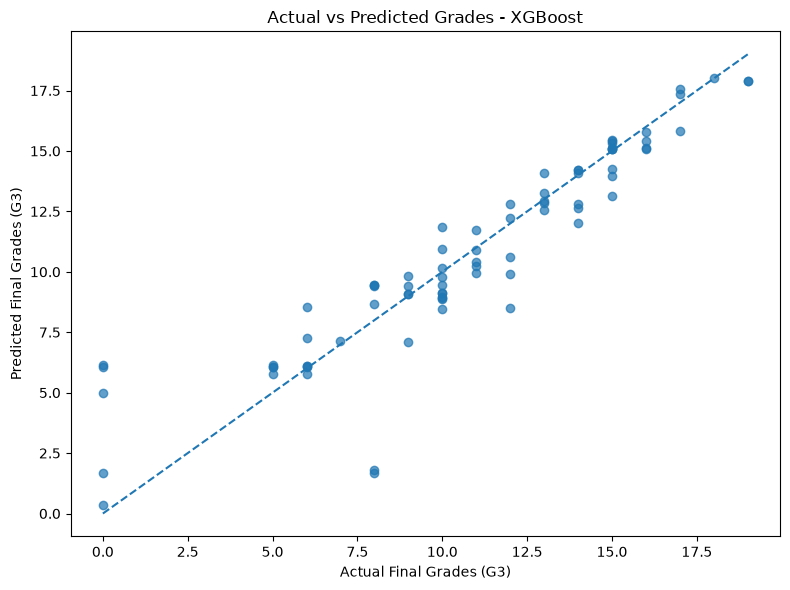

In [24]:
import matplotlib.pyplot as plt

# Plot actual grades against predicted grades
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_raw,
    y_test_pred,
    alpha=0.7
)

# Add reference line for perfect predictions
min_grade = min(y_test_raw.min(), y_test_pred.min())
max_grade = max(y_test_raw.max(), y_test_pred.max())

plt.plot(
    [min_grade, max_grade],
    [min_grade, max_grade],
    linestyle="--"
)

plt.xlabel("Actual Final Grades (G3)")
plt.ylabel("Predicted Final Grades (G3)")
plt.title("Actual vs Predicted Grades - XGBoost")

plt.tight_layout()
plt.show()

Actual vs Predicted Plot Interpretation

The Actual vs Predicted plot shows that most predictions are reasonably close to the diagonal reference line, indicating that the XGBoost model captures the general relationship between the selected features and students' final grades.

However, some observations are considerably distant from the reference line, indicating larger prediction errors. The model also shows both overprediction and underprediction in different observations.

This suggests that although the model demonstrates good overall predictive performance, it does not predict every student's final grade accurately. Further residual analysis is therefore necessary to investigate the distribution and magnitude of prediction errors.

In [25]:
# Calculate residuals using existing predictions
residuals = y_test_raw - y_test_pred

# Create a dataframe for error analysis
residuals_df = pd.DataFrame({
    "Actual Grade": y_test_raw.values,
    "Predicted Grade": y_test_pred,
    "Residual": residuals
})

# Display the first ten observations
display(residuals_df.head(10))

,Actual Grade,Predicted Grade,Residual
0,10,8.885940,1.114060
1,12,12.240387,-0.240387
2,5,5.789812,-0.789812
3,10,9.127542,0.872458
4,9,9.069506,-0.069506
5,13,12.867843,0.132157
6,18,18.000845,-0.000845
7,6,7.263381,-1.263381
8,0,4.992096,-4.992096
9,14,12.660299,1.339701


Residual Analysis Interpretation

The residual table demonstrates that the model produces both positive and negative prediction errors. Positive residuals indicate underprediction, while negative residuals indicate overprediction.

Most of the displayed observations have relatively small residuals. However, the observation with an actual grade of zero has a residual of approximately -4.99, indicating a significant overprediction.

This suggests that the model may have difficulty predicting certain student outcomes, particularly some unusually low final grades. Further analysis of the residual distribution is required to understand the overall error pattern.

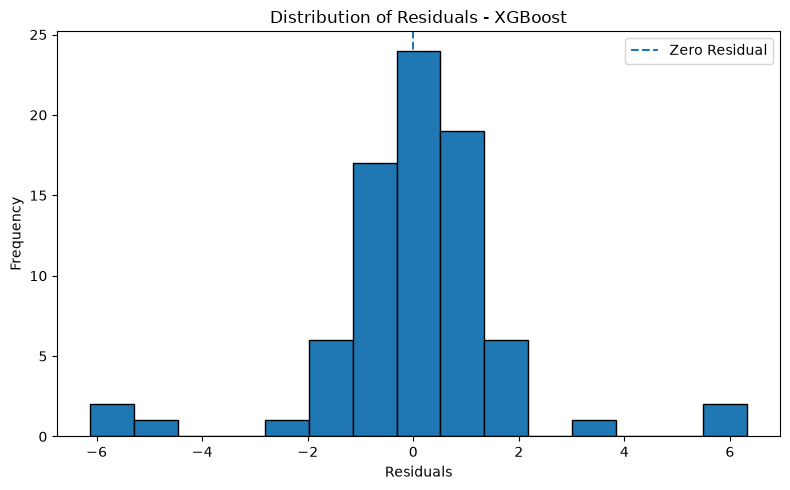

In [26]:
# Plot the distribution of residuals
plt.figure(figsize=(8, 5))

plt.hist(
    residuals,
    bins=15,
    edgecolor="black"
)

# Add a reference line at zero
plt.axvline(
    x=0,
    linestyle="--",
    label="Zero Residual"
)

plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals - XGBoost")
plt.legend()

plt.tight_layout()
plt.show()

Residual Distribution Interpretation

The residual histogram shows that most prediction errors are concentrated around zero, indicating that the model generally produces predictions close to the actual student grades.

However, a few observations have relatively large residuals, extending to approximately -6 and +6. These indicate instances of substantial overprediction and underprediction.

The distribution is not perfectly symmetrical, suggesting some variation in the model's prediction errors. Overall, the model demonstrates reasonable predictive performance, although some individual predictions require further investigation.

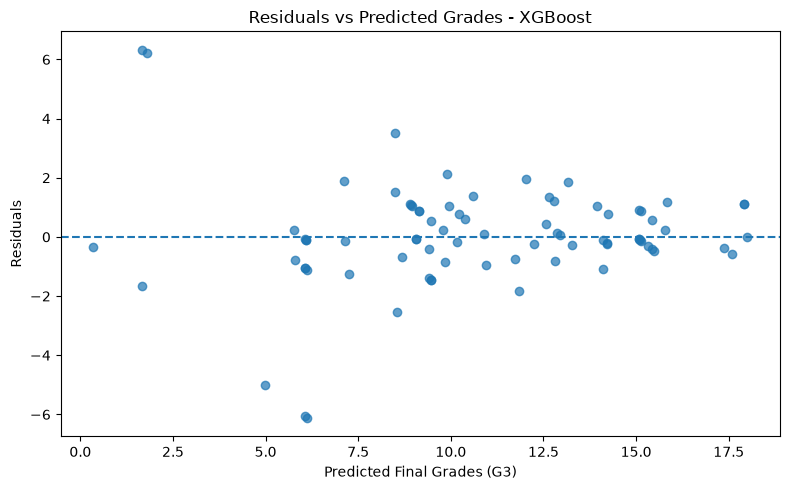

In [27]:
# Plot residuals against predicted grades
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test_pred,
    residuals,
    alpha=0.7
)

# Add zero reference line
plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Final Grades (G3)")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Grades - XGBoost")

plt.tight_layout()
plt.show()

Residuals vs Predicted Values Interpretation

The residuals vs predicted values plot shows that most observations are distributed around the zero reference line, indicating that the model does not consistently overpredict or underpredict grades across the entire prediction range.

However, several observations have relatively large residuals, particularly in the lower predicted-grade region. These indicate that the model struggles with certain student outcomes.

The plot also suggests some variation in prediction errors across different predicted-grade levels. Overall, the model captures the general relationship between the selected features and final grades, but some individual predictions remain inaccurate.

In [28]:
# Calculate absolute prediction errors
residuals_df["Absolute Error"] = residuals_df["Residual"].abs()

# Sort observations by largest prediction error
largest_errors = residuals_df.sort_values(
    by="Absolute Error",
    ascending=False
)

# Display the ten observations with the largest errors
display(largest_errors.head(10))

,Actual Grade,Predicted Grade,Residual,Absolute Error
34,8,1.673353,6.326647,6.326647
16,8,1.793802,6.206198,6.206198
24,0,6.124686,-6.124686,6.124686
19,0,6.066649,-6.066649,6.066649
8,0,4.992096,-4.992096,4.992096
27,12,8.495780,3.504220,3.504220
70,6,8.541737,-2.541737,2.541737
52,12,9.890069,2.109931,2.109931
38,14,12.036690,1.963310,1.963310
64,9,7.108244,1.891756,1.891756


Analysis of the Largest Prediction Errors

The error analysis reveals that the XGBoost model produces its largest prediction errors for certain students with relatively low final grades.

Two observations with actual grades of 8 were significantly underpredicted, with absolute errors exceeding 6 grade points. Additionally, three observations with actual grades of zero were overpredicted, with predictions ranging from approximately 5 to 6.

These findings suggest that the model struggles to accurately predict certain low-grade outcomes. However, substantial errors were also observed among students with higher actual grades.

This indicates that the model captures the general relationship between the selected features and final grades but may not fully capture individual differences in student performance.

In [29]:
# Identify the original test observations with the largest errors
largest_error_indices = largest_errors.head(10).index

# Retrieve their original feature values
error_analysis = test_df.loc[
    largest_error_indices,
    features + ["G3"]
].copy()

# Add predictions and errors
error_analysis["Predicted Grade"] = y_test_pred[
    largest_error_indices
]

error_analysis["Absolute Error"] = largest_errors.loc[
    largest_error_indices,
    "Absolute Error"
]

display(error_analysis)

,studytime,absences,G1,G2,G3,Predicted Grade,Absolute Error
34,3,0,7,7,8,1.673353,6.326647
16,2,0,8,7,8,1.793802,6.206198
24,4,0,7,9,0,6.124686,6.124686
19,4,0,10,9,0,6.066649,6.066649
8,2,0,8,8,0,4.992096,4.992096
27,2,0,8,10,12,8.495780,3.504220
70,2,8,8,8,6,8.541737,2.541737
52,2,0,9,11,12,9.890069,2.109931
38,1,2,12,12,14,12.036690,1.963310
64,2,4,7,7,9,7.108244,1.891756


### Interpretation of Feature Patterns in Large Prediction Errors

The examination of the largest prediction errors reveals several patterns in the selected input features.

Some students with actual final grades of zero had non-zero grades in their previous examinations (G1 and G2). The model predicted grades between approximately 5 and 6 for these observations, resulting in substantial overprediction.

Additionally, two students with actual final grades of 8 were predicted to receive grades below 2. This indicates that the model sometimes underestimates students whose final examination performance improves compared with their previous examination results.

These findings suggest that the selected features do not fully capture all the factors associated with students' final academic performance. In particular, the model may have difficulty identifying unusual changes between previous and final examination outcomes.

Further improvements could involve investigating additional relevant features and evaluating alternative model configurations using cross-validation on the training dataset.

In [30]:
# Count students with zero final grades in training data
zero_grades = (y_train_raw == 0).sum()

# Calculate the percentage
zero_percentage = (zero_grades / len(y_train_raw)) * 100

print("Training Dataset Grade Analysis")
print("--------------------------------")
print("Total training observations:", len(y_train_raw))
print("Students with G3 = 0:", zero_grades)
print("Percentage with G3 = 0:", round(zero_percentage, 2), "%")

# Display descriptive statistics
print("\nFinal Grade Statistics:")
display(y_train_raw.describe())

Training Dataset Grade Analysis
--------------------------------
Total training observations: 316
Students with G3 = 0: 33
Percentage with G3 = 0: 10.44 %

Final Grade Statistics:


count    316.000000
mean      10.325949
std        4.590337
min        0.000000
25%        8.000000
50%       11.000000
75%       13.000000
max       20.000000
Name: G3, dtype: float64

Interpretation of Training Data Grade Distribution

The training dataset contains 316 observations, of which 33 students (10.44%) received a final grade of zero.

The mean final grade is approximately 10.33, while the median is 11. The grades range from 0 to 20, with a standard deviation of approximately 4.59.

The presence of zero-grade observations in the training dataset indicates that the model has encountered such outcomes during training. However, the previous error analysis shows that it still struggles to identify some students who ultimately receive zero grades.

This suggests that the selected predictors may not fully capture the factors associated with these outcomes.

In [31]:
# Create two groups using training data only
zero_grade_students = train_df[train_df["G3"] == 0]

positive_grade_students = train_df[train_df["G3"] > 0]

# Compare previous examination grades
comparison = pd.DataFrame({
    "Zero Final Grade": zero_grade_students[["G1", "G2"]].mean(),
    "Positive Final Grade": positive_grade_students[["G1", "G2"]].mean()
})

print("Average Previous Grades by Final Grade Group:")
display(comparison.round(2))

Average Previous Grades by Final Grade Group:


,Zero Final Grade,Positive Final Grade
G1,7.61,11.32
G2,4.36,11.39


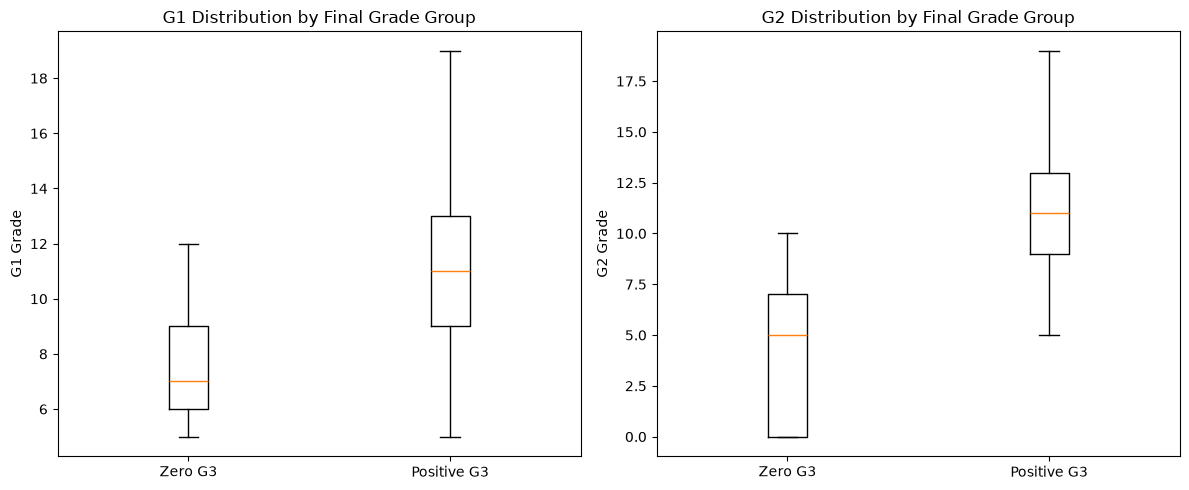

In [32]:
# Compare G1 and G2 distributions by final grade group
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# G1 comparison
axes[0].boxplot([
    zero_grade_students["G1"],
    positive_grade_students["G1"]
])

axes[0].set_xticks([1, 2])
axes[0].set_xticklabels(["Zero G3", "Positive G3"])
axes[0].set_title("G1 Distribution by Final Grade Group")
axes[0].set_ylabel("G1 Grade")

# G2 comparison
axes[1].boxplot([
    zero_grade_students["G2"],
    positive_grade_students["G2"]
])

axes[1].set_xticks([1, 2])
axes[1].set_xticklabels(["Zero G3", "Positive G3"])
axes[1].set_title("G2 Distribution by Final Grade Group")
axes[1].set_ylabel("G2 Grade")

plt.tight_layout()
plt.show()

Interpretation of Previous Grade Distributions

The boxplots reveal noticeable differences in the previous examination grades of students with zero and positive final grades.

Students with zero final grades generally have lower G1 and G2 values than students with positive final grades. The median G1 is approximately 7 for the zero-grade group and 11 for the positive-grade group. Similarly, the median G2 is approximately 5 and 11, respectively.

The G2 distributions show a particularly noticeable separation between the groups, supporting its importance as a predictor of final academic performance.

However, the distributions overlap, indicating that some students with relatively high previous examination grades still receive zero final grades. This suggests that previous examination performance alone cannot fully explain every final outcome.

In [33]:
# Calculate average final grade by number of previous failures
failure_analysis = train_df.groupby("failures")["G3"].agg(
    ["count", "mean", "median"]
).reset_index()

print("Final Grade Performance by Previous Failures:")
display(failure_analysis.round(2))

Final Grade Performance by Previous Failures:


,failures,count,mean,median
0,0,247,11.19,11.0
1,1,45,8.16,10.0
2,2,11,6.00,7.0
3,3,13,5.08,7.0


In [34]:
# Original feature set
X_train_original = train_df[features]

# Expanded feature set
expanded_features = features + ["failures"]

X_train_extended = train_df[expanded_features]

# Define the XGBoost model using our best hyperparameters
xgb_best_params = {
    "n_estimators": 100,
    "learning_rate": 0.05,
    "max_depth": 2,
    "random_state": 42,
    "objective": "reg:squarederror"
}

print("Original features:", X_train_original.shape)
print("Expanded features:", X_train_extended.shape)

Original features: (316, 4)
Expanded features: (316, 5)


In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Preprocessor for the original four features
preprocessor_original = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), features)
])

# Preprocessor for the expanded five features
preprocessor_extended = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), expanded_features)
])

print("Both preprocessing pipelines created successfully!")

Both preprocessing pipelines created successfully!


In [36]:
from sklearn.model_selection import cross_val_score
from xgboost import XGBRegressor
import numpy as np

# Create the original model pipeline
original_pipeline = Pipeline([
    ("preprocessor", preprocessor_original),
    ("model", XGBRegressor(**xgb_best_params))
])

# Create the expanded model pipeline
extended_pipeline = Pipeline([
    ("preprocessor", preprocessor_extended),
    ("model", XGBRegressor(**xgb_best_params))
])

# Evaluate original feature set
original_scores = cross_val_score(
    original_pipeline,
    X_train_original,
    y_train_raw,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

# Evaluate expanded feature set
extended_scores = cross_val_score(
    extended_pipeline,
    X_train_extended,
    y_train_raw,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

# Compare positive MAE values
comparison_results = pd.DataFrame({
    "Feature Set": ["Original (4 features)", "Expanded (5 features)"],
    "Mean MAE": [
        -original_scores.mean(),
        -extended_scores.mean()
    ],
    "Standard Deviation": [
        original_scores.std(),
        extended_scores.std()
    ]
})

display(comparison_results.round(4))

,Feature Set,Mean MAE,Standard Deviation
0,Original (4 features),0.9597,0.2015
1,Expanded (5 features),0.9682,0.1880


In [37]:
from sklearn.model_selection import GridSearchCV

# Create the expanded XGBoost pipeline
expanded_xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor_extended),
    ("model", XGBRegressor(
        random_state=42,
        objective="reg:squarederror"
    ))
])

# Define the hyperparameter search space
expanded_param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__max_depth": [2, 3, 4]
}

# Configure GridSearchCV
expanded_grid_search = GridSearchCV(
    estimator=expanded_xgb_pipeline,
    param_grid=expanded_param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1,
    refit=True
)

print("Expanded model tuning configured successfully!")

Expanded model tuning configured successfully!


In [38]:
# Tune using training data only
expanded_grid_search.fit(
    X_train_extended,
    y_train_raw
)

print("Expanded model tuning completed successfully!")

Expanded model tuning completed successfully!


In [39]:
print("Best Expanded Model Hyperparameters:")
print(expanded_grid_search.best_params_)

print("\nBest Expanded Model Cross-Validation MAE:")
print(-expanded_grid_search.best_score_)

print("\nOriginal Model Cross-Validation MAE:")
print(-grid_search.best_score_)

Best Expanded Model Hyperparameters:
{'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 100}

Best Expanded Model Cross-Validation MAE:
0.9682210445404053

Original Model Cross-Validation MAE:
0.9597055077552795


#### Interpretation of Expanded Model Hyperparameter Tuning

The expanded XGBoost model was further optimized using GridSearchCV with five-fold cross-validation on the training dataset.

The best hyperparameters were 100 estimators, a learning rate of 0.05 and a maximum tree depth of 2. These were identical to the optimal hyperparameters obtained for the original model.

The expanded model achieved a cross-validation MAE of 0.9682, compared with 0.9597 for the original four-feature model.

These results demonstrate that neither adding the `failures` feature nor independently tuning the expanded model improved its average cross-validation performance.

Therefore, the original four-feature XGBoost model is retained as the preferred model. This experiment demonstrates the importance of evaluating feature selection and hyperparameter configurations using cross-validation rather than assuming that additional features will improve predictive performance.

###  Summary of Model Improvement Experiments

Several experiments were conducted to investigate whether the predictive performance of the tuned XGBoost model could be improved.

First, the distribution of final grades in the training dataset was examined. A total of 33 students (10.44%) had a final grade of zero.

Previous examination grades were also compared between students with zero and positive final grades. The analysis showed that students with zero final grades generally had lower G1 and G2 values.

The relationship between previous academic failures and final grades was subsequently investigated. Students with more previous failures generally had lower average final grades, suggesting that `failures` could provide additional predictive information.

However, adding `failures` to the original four predictors did not improve cross-validation performance. The original model achieved an MAE of 0.9597, while the expanded model achieved an MAE of 0.9682.

Further hyperparameter tuning of the expanded model also failed to improve its performance. Consequently, the original four-feature XGBoost model was retained as the final model.

These experiments demonstrate the importance of evaluating potential improvements using cross-validation and selecting features based on their contribution to predictive performance rather than simply increasing the number of predictors.

### Limitation of Model Evaluation

The dataset was initially divided into training and testing sets using an 80:20 split. However, the testing dataset was used during earlier model comparisons in Unit 3 and subsequent diagnostic analyses.

Although cross-validation and hyperparameter tuning were conducted using the training dataset, repeated evaluation on the same testing observations means that the test set cannot be considered a completely untouched final evaluation dataset.

Therefore, the reported test metrics should be interpreted as performance measurements on the available testing observations rather than a fully independent estimate of generalization performance.

Future work could address this limitation by reserving a new independent testing dataset for final model evaluation.